>>> [1/4] INGESTION & SANITIZATION
    - Population defined: 217 sovereign/territorial entities.
    - Analytical Dataset: 12091 observations.
>>> [2/4] FEATURE ENGINEERING
>>> [3/4] MULTIVARIATE STRUCTURE (PCA) - Year 2010


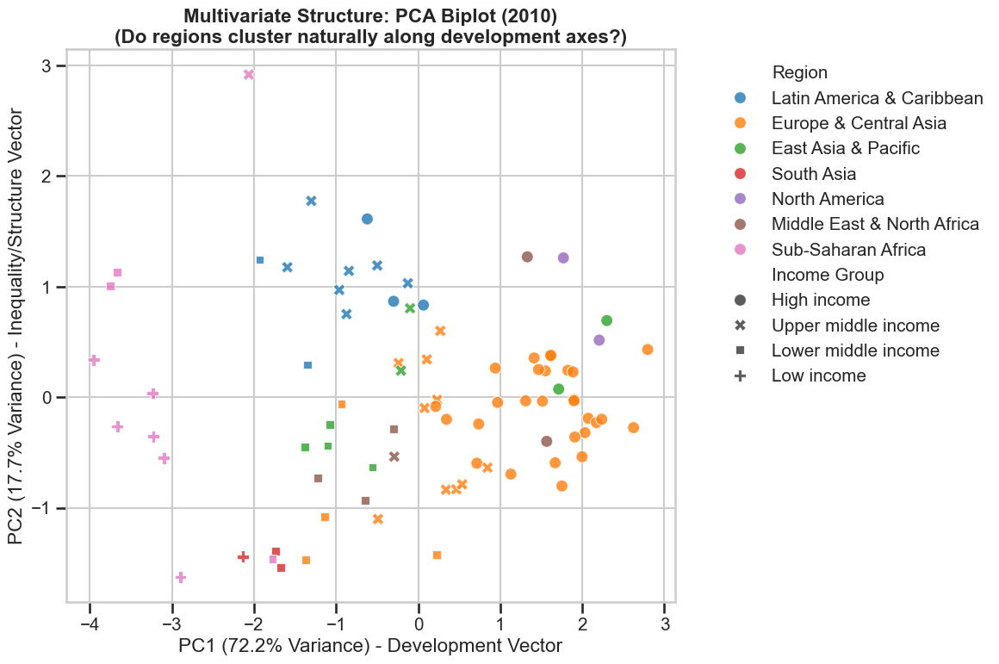

>>> [4/4] VISUALIZING TENSIONS - Year 2010


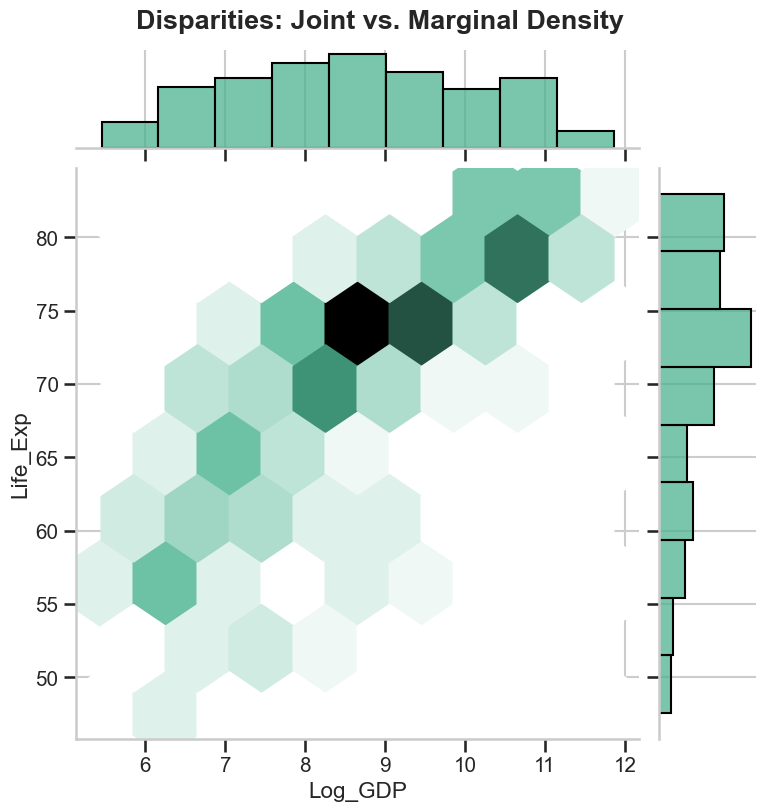

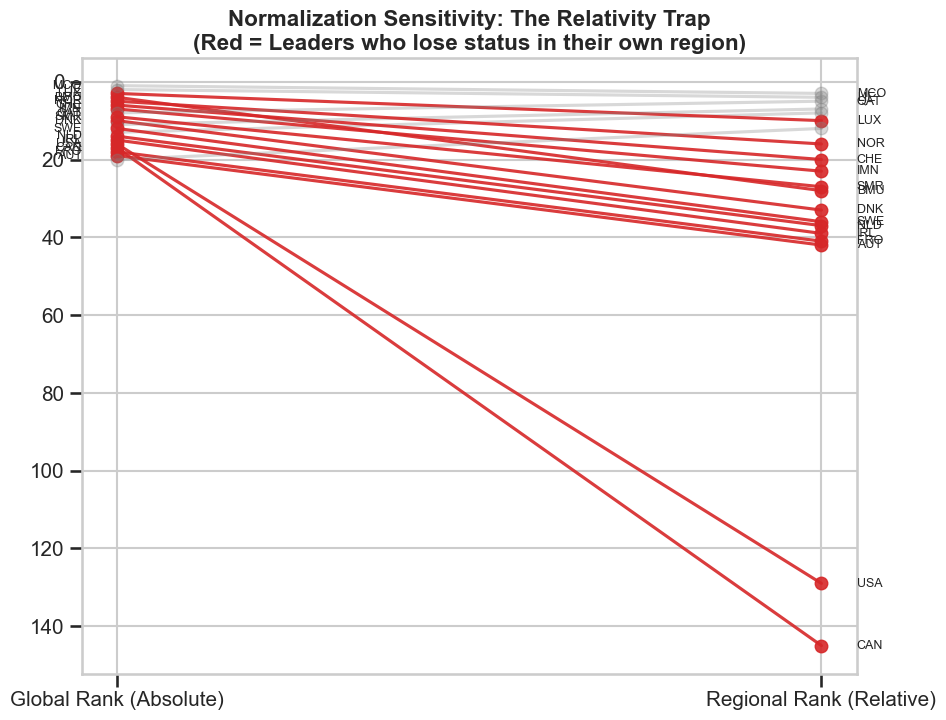

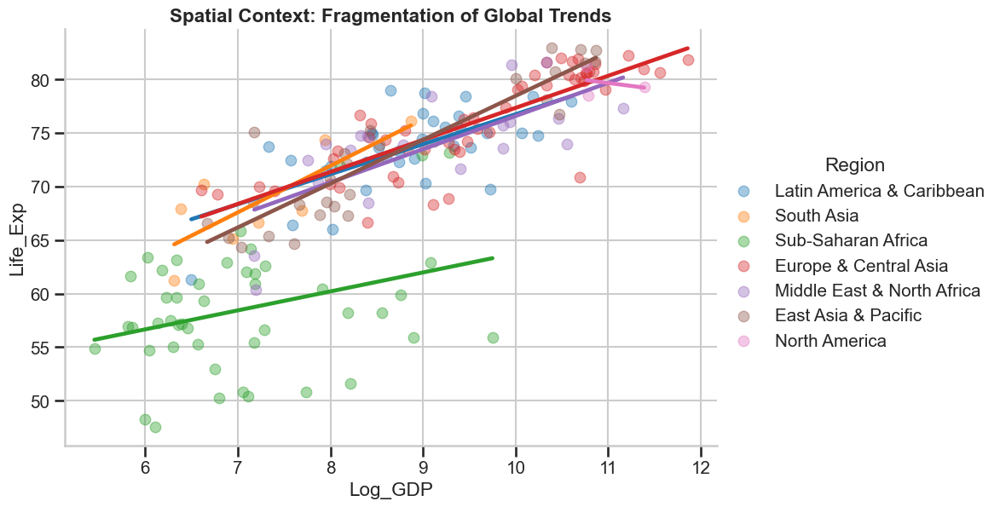

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import warnings

# --------------------------------------------------------------------------------
# CONFIGURATION
# --------------------------------------------------------------------------------
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_context("talk", font_scale=0.9)

class MasterclassEDA:
    def __init__(self):
        self.df_meta = None
        self.merged = None
        
    def ingest_and_sanitize(self):
        """
        [1/4] INGESTION: DEFINING THE POPULATION
        Filters out 'Aggregates' (e.g., World, Arab World) that bias variance.
        """
        print(">>> [1/4] INGESTION & SANITIZATION")
        
        # 1. Load Metadata
        try:
            self.df_meta = pd.read_csv('WDICountry.csv')
            # Critical Filter: Entities with no Region are Aggregates
            valid_entities = self.df_meta[self.df_meta['Region'].notna()][['Country Code', 'Region', 'Income Group']]
            print(f"    - Population defined: {len(valid_entities)} sovereign/territorial entities.")
        except FileNotFoundError:
            raise RuntimeError("CRITICAL: WDICountry.csv missing.")

        # 2. Load Data
        try:
            df_raw = pd.read_csv('WDIData.csv')
        except FileNotFoundError:
            raise RuntimeError("CRITICAL: WDIData.csv missing.")

        # 3. Targeted Extraction (Memory Optimization)
        # We focus on the 'Development Triad': Economic (GDP), Social (Life Exp), Environmental (CO2)
        indicators = {
            'NY.GDP.PCAP.CD': 'GDP_PC',
            'SP.DYN.LE00.IN': 'Life_Exp',
            'EN.ATM.CO2E.PC': 'CO2_PC',
            'SI.POV.GINI': 'Gini'
        }
        
        df_sub = df_raw[df_raw['Indicator Code'].isin(indicators.keys())]
        
        # 4. Reshape to Tidy Format
        id_vars = ['Country Code', 'Indicator Code']
        value_vars = [c for c in df_sub.columns if c.isdigit() or c.startswith('YR')]
        
        df_long = df_sub.melt(id_vars=id_vars, value_vars=value_vars, var_name='Year', value_name='Value')
        # Extract integer year
        df_long['Year'] = df_long['Year'].astype(str).str.extract(r'(\d+)').astype(int)
        
        # Pivot to Wide
        df_pivot = df_long.pivot_table(index=['Country Code', 'Year'], columns='Indicator Code', values='Value').reset_index()
        df_pivot.rename(columns=indicators, inplace=True)
        
        # 5. Merge Context
        self.merged = df_pivot.merge(valid_entities, on='Country Code', how='inner')
        print(f"    - Analytical Dataset: {self.merged.shape[0]} observations.")

    def construct_analytical_features(self):
        """
        [2/4] FEATURE ENGINEERING: THE ANALYTICAL LENS
        Constructs 'Structural' (Log) and 'Relative' (Regional Z-Score) features.
        """
        print(">>> [2/4] FEATURE ENGINEERING")
        
        # Log Transforms (Wealth/Emissions are log-normal, not linear)
        self.merged['Log_GDP'] = np.log1p(self.merged['GDP_PC'])
        self.merged['Log_CO2'] = np.log1p(self.merged['CO2_PC'])
        
        # Relative Wealth: "Are you rich for your neighborhood?"
        # Z-score of GDP within that Region and Year
        self.merged['GDP_Regional_Z'] = self.merged.groupby(['Region', 'Year'])['GDP_PC'] \
            .transform(lambda x: (x - x.mean()) / x.std())

    def analyze_multivariate_structure(self, year=2018):
        """
        [3/4] MULTIVARIATE STRUCTURE (PCA)
        Visualizes whether 'Regions' are statistically real clusters.
        """
        print(f">>> [3/4] MULTIVARIATE STRUCTURE (PCA) - Year {year}")
        
        # Prepare Data (Must be complete for PCA)
        df_pca = self.merged[self.merged['Year'] == year].dropna(subset=['GDP_PC', 'Life_Exp', 'CO2_PC', 'Gini'])
        
        if len(df_pca) < 10:
            print(f"    ! Insufficient complete data for PCA in {year}. Skipping.")
            return

        features = ['Log_GDP', 'Life_Exp', 'Log_CO2', 'Gini']
        X = StandardScaler().fit_transform(df_pca[features])
        
        pca = PCA(n_components=2)
        components = pca.fit_transform(X)
        
        df_pca['PC1'] = components[:,0]
        df_pca['PC2'] = components[:,1]
        
        # VISUAL 1: PCA Biplot
        plt.figure(figsize=(12, 8))
        sns.scatterplot(data=df_pca, x='PC1', y='PC2', hue='Region', style='Income Group', alpha=0.8, s=100)
        plt.title(f"Multivariate Structure: PCA Biplot ({year})\n(Do regions cluster naturally along development axes?)", fontweight='bold')
        plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} Variance) - Development Vector")
        plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} Variance) - Inequality/Structure Vector")
        plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.tight_layout()
        plt.show()

    def analyze_analytical_tensions(self, year=2018):
        """
        [4/4] VISUALIZING TENSIONS & DISPARITIES
        Explicitly addresses the required analytical tensions.
        """
        print(f">>> [4/4] VISUALIZING TENSIONS - Year {year}")
        df_snap = self.merged[self.merged['Year'] == year].copy()
        
        if df_snap.empty:
            print("    ! Critical: No data for this year.")
            return

        # --- VISUAL 2: INDIVIDUAL VS JOINT (Robust JointPlot) ---
        # FIX: Drop NaNs specifically for the plotted vars to avoid 'unsized object' error
        joint_data = df_snap[['Log_GDP', 'Life_Exp']].dropna()
        
        if len(joint_data) > 10:
            g = sns.jointplot(data=joint_data, x='Log_GDP', y='Life_Exp', kind='hex', height=8, color='#4CB391')
            g.fig.suptitle("Disparities: Joint vs. Marginal Density", y=1.02, fontweight='bold')
            plt.show()
        else:
            print("    ! Insufficient data for Hex JointPlot (needs N>10).")

        # --- VISUAL 3: NORMALIZATION SENSITIVITY (Rank Volatility) ---
        # How does 'Success' change when viewed Locally vs Globally?
        df_rank = df_snap.dropna(subset=['GDP_PC', 'GDP_Regional_Z'])
        
        if len(df_rank) > 10:
            df_rank['Rank_Global'] = df_rank['GDP_PC'].rank(ascending=False)
            df_rank['Rank_Regional'] = df_rank['GDP_Regional_Z'].rank(ascending=False)
            
            # Filter to top 20 Global Economies to see if they stay on top regionally
            top_movers = df_rank[df_rank['Rank_Global'] <= 20].copy()
            
            plt.figure(figsize=(10, 8))
            for i, row in top_movers.iterrows():
                # Color Red if they drop significantly in regional standing
                is_drop = row['Rank_Regional'] > row['Rank_Global'] + 5
                color = '#d62728' if is_drop else '#7f7f7f'
                alpha = 0.9 if is_drop else 0.3
                
                plt.plot([1, 2], [row['Rank_Global'], row['Rank_Regional']], marker='o', color=color, alpha=alpha)
                
                # Label interesting cases
                if row['Rank_Global'] <= 10 or is_drop:
                    plt.text(0.95, row['Rank_Global'], row['Country Code'], ha='right', va='center', fontsize=9)
                    plt.text(2.05, row['Rank_Regional'], row['Country Code'], ha='left', va='center', fontsize=9)
                    
            plt.xticks([1, 2], ['Global Rank (Absolute)', 'Regional Rank (Relative)'])
            plt.gca().invert_yaxis() # Rank 1 is top
            plt.title("Normalization Sensitivity: The Relativity Trap\n(Red = Leaders who lose status in their own region)", fontweight='bold')
            plt.show()

        # --- VISUAL 4: SPATIAL CONTEXT (Simpson's Paradox Check) ---
        # Does spatial context reinforce or weaken the global conclusion?
        reg_data = df_snap[['Log_GDP', 'Life_Exp', 'Region']].dropna()
        if len(reg_data) > 20:
            sns.lmplot(data=reg_data, x='Log_GDP', y='Life_Exp', hue='Region', ci=None, height=6, aspect=1.5, 
                       scatter_kws={'alpha':0.4})
            plt.title("Spatial Context: Fragmentation of Global Trends", fontweight='bold')
            plt.show()

if __name__ == "__main__":
    eda = MasterclassEDA()
    eda.ingest_and_sanitize()
    eda.construct_analytical_features()
    # Try 2018; if your dataset ends earlier, adjust this year.
    eda.analyze_multivariate_structure(year=2010)
    eda.analyze_analytical_tensions(year=2010)

>>> [1/4] INGESTION & SANITIZATION
    - Analytical Dataset: 12091 pooled observations (All Years).
>>> [2/4] FEATURE ENGINEERING
>>> [3/4] MULTIVARIATE STRUCTURE (PCA) - POOLED DATA


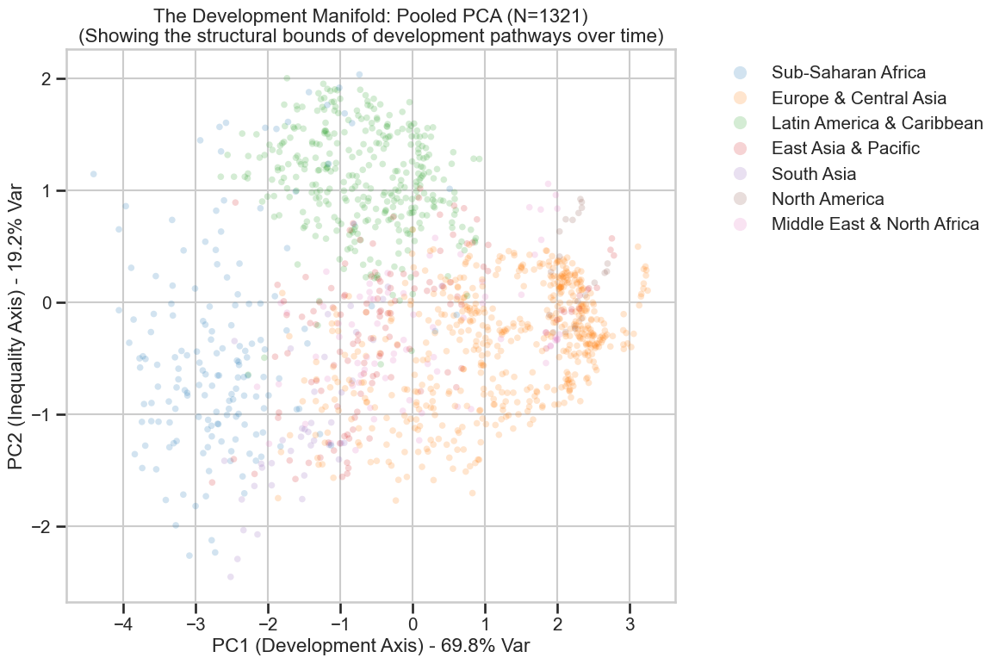

>>> [4/4] VISUALIZING TENSIONS - ALL YEARS


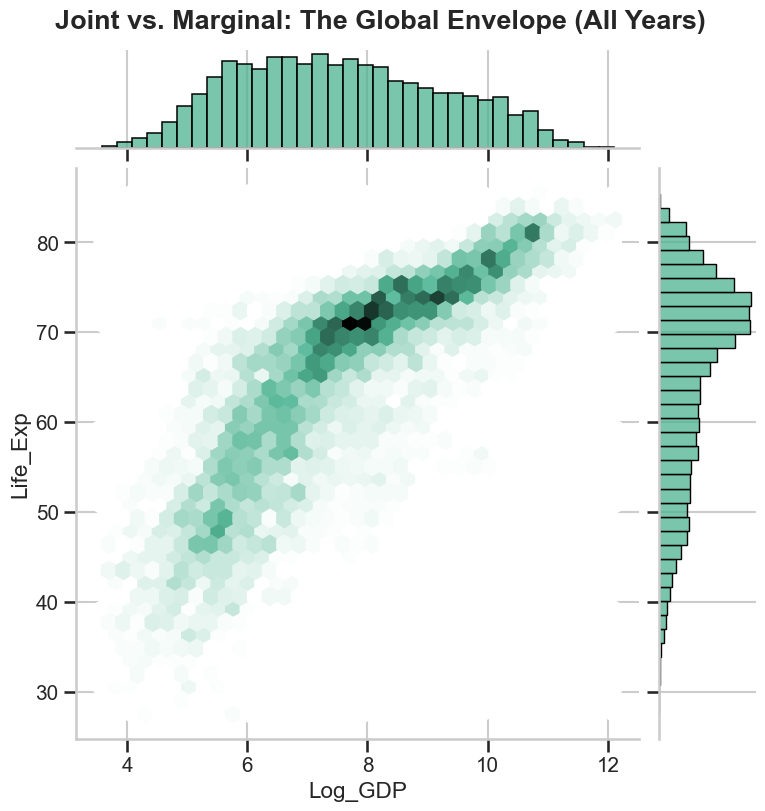

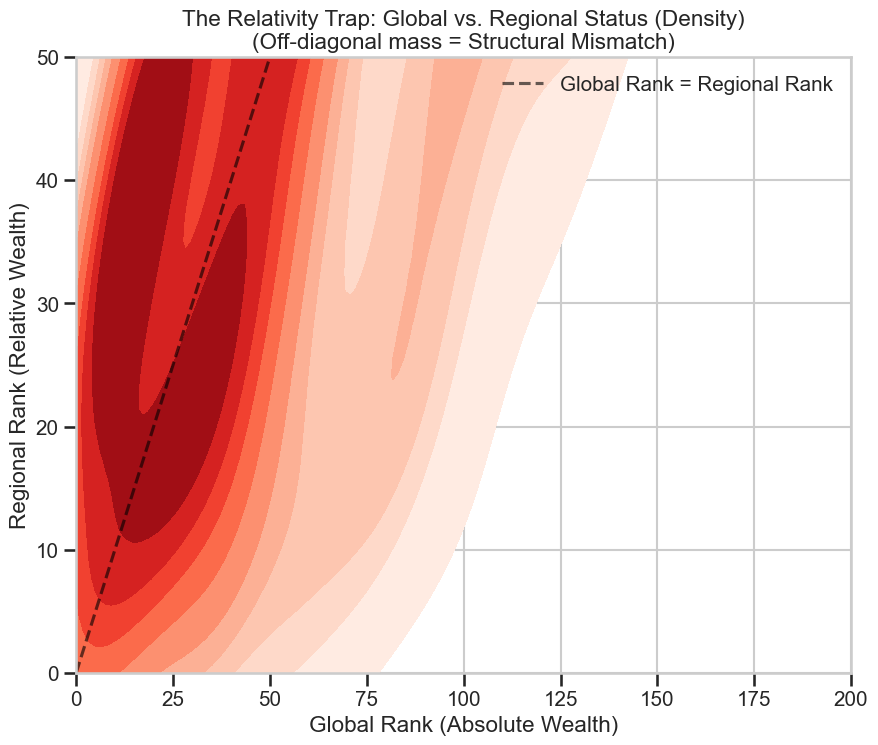

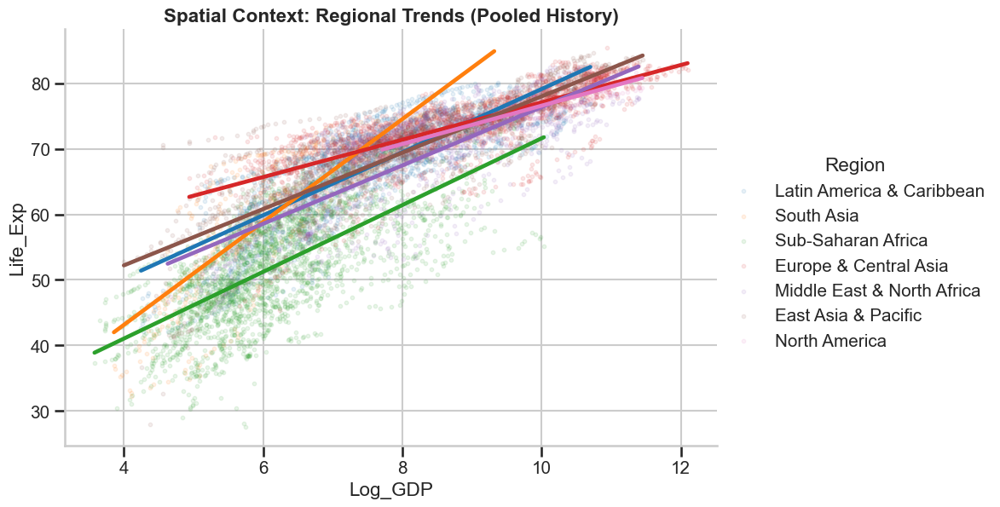

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import warnings

# --------------------------------------------------------------------------------
# CONFIGURATION
# --------------------------------------------------------------------------------
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_context("talk", font_scale=0.9)

class MasterclassEDA:
    def __init__(self):
        self.df_meta = None
        self.merged = None
        
    def ingest_and_sanitize(self):
        """
        [1/4] INGESTION: DEFINING THE POPULATION
        """
        print(">>> [1/4] INGESTION & SANITIZATION")
        
        # 1. Load Metadata
        try:
            self.df_meta = pd.read_csv('WDICountry.csv')
            # Critical Filter: Entities with no Region are Aggregates
            valid_entities = self.df_meta[self.df_meta['Region'].notna()][['Country Code', 'Region', 'Income Group']]
        except FileNotFoundError:
            raise RuntimeError("CRITICAL: WDICountry.csv missing.")

        # 2. Load Data
        try:
            df_raw = pd.read_csv('WDIData.csv')
        except FileNotFoundError:
            raise RuntimeError("CRITICAL: WDIData.csv missing.")

        # 3. Targeted Extraction
        indicators = {
            'NY.GDP.PCAP.CD': 'GDP_PC',
            'SP.DYN.LE00.IN': 'Life_Exp',
            'EN.ATM.CO2E.PC': 'CO2_PC',
            'SI.POV.GINI': 'Gini'
        }
        
        df_sub = df_raw[df_raw['Indicator Code'].isin(indicators.keys())]
        
        # 4. Reshape to Tidy Format (Melting Years)
        id_vars = ['Country Code', 'Indicator Code']
        value_vars = [c for c in df_sub.columns if c.isdigit() or c.startswith('YR')]
        
        df_long = df_sub.melt(id_vars=id_vars, value_vars=value_vars, var_name='Year', value_name='Value')
        df_long['Year'] = df_long['Year'].astype(str).str.extract(r'(\d+)').astype(int)
        
        df_pivot = df_long.pivot_table(index=['Country Code', 'Year'], columns='Indicator Code', values='Value').reset_index()
        df_pivot.rename(columns=indicators, inplace=True)
        
        # 5. Merge Context
        self.merged = df_pivot.merge(valid_entities, on='Country Code', how='inner')
        print(f"    - Analytical Dataset: {self.merged.shape[0]} pooled observations (All Years).")

    def construct_analytical_features(self):
        """
        [2/4] FEATURE ENGINEERING
        """
        print(">>> [2/4] FEATURE ENGINEERING")
        # Log Transforms
        self.merged['Log_GDP'] = np.log1p(self.merged['GDP_PC'])
        self.merged['Log_CO2'] = np.log1p(self.merged['CO2_PC'])
        
        # Relative Wealth (Z-score within Region AND Year)
        # This normalizes "Wealth" relative to the peer group at that specific time
        self.merged['GDP_Regional_Z'] = self.merged.groupby(['Region', 'Year'])['GDP_PC'] \
            .transform(lambda x: (x - x.mean()) / x.std())

    def analyze_multivariate_structure(self):
        """
        [3/4] POOLED MULTIVARIATE STRUCTURE (PCA)
        Analyzing the 'Shape' of development across all time periods.
        """
        print(f">>> [3/4] MULTIVARIATE STRUCTURE (PCA) - POOLED DATA")
        
        # Drop NaNs to perform PCA
        df_pca = self.merged.dropna(subset=['GDP_PC', 'Life_Exp', 'CO2_PC', 'Gini'])
        
        if len(df_pca) < 50:
            print("    ! Insufficient data for pooled PCA.")
            return

        features = ['Log_GDP', 'Life_Exp', 'Log_CO2', 'Gini']
        X = StandardScaler().fit_transform(df_pca[features])
        pca = PCA(n_components=2)
        components = pca.fit_transform(X)
        
        df_pca['PC1'] = components[:,0]
        df_pca['PC2'] = components[:,1]
        
        plt.figure(figsize=(12, 8))
        # Visualization: Use low alpha to show density of the "Development Cloud"
        sns.scatterplot(data=df_pca, x='PC1', y='PC2', hue='Region', alpha=0.2, s=30, linewidth=0)
        plt.title(f"The Development Manifold: Pooled PCA (N={len(df_pca)})\n(Showing the structural bounds of development pathways over time)")
        plt.xlabel(f"PC1 (Development Axis) - {pca.explained_variance_ratio_[0]:.1%} Var")
        plt.ylabel(f"PC2 (Inequality Axis) - {pca.explained_variance_ratio_[1]:.1%} Var")
        plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', markerscale=2)
        plt.tight_layout()
        plt.show()

    def analyze_analytical_tensions(self):
        """
        [4/4] VISUALIZING TENSIONS - FULL DATASET
        """
        print(f">>> [4/4] VISUALIZING TENSIONS - ALL YEARS")
        
        # --- VISUAL 2: JOINT PLOT (Pooled Hexbin) ---
        # Shows the global envelope of Health vs Wealth
        joint_data = self.merged[['Log_GDP', 'Life_Exp']].dropna()
        if not joint_data.empty:
            g = sns.jointplot(data=joint_data, x='Log_GDP', y='Life_Exp', kind='hex', height=8, color='#4CB391')
            g.fig.suptitle("Joint vs. Marginal: The Global Envelope (All Years)", y=1.02, fontweight='bold')
            plt.show()

        # --- VISUAL 3: RELATIVITY TRAP (Rank Density) ---
        # Instead of slope graph (messy for N=10k), we use Density of Ranks
        df_rank = self.merged.dropna(subset=['GDP_PC', 'GDP_Regional_Z']).copy()
        if not df_rank.empty:
            # Calculate ranks per year to ensure fair comparison
            df_rank['Rank_Global'] = df_rank.groupby('Year')['GDP_PC'].rank(ascending=False)
            df_rank['Rank_Regional'] = df_rank.groupby('Year')['GDP_Regional_Z'].rank(ascending=False)
            
            plt.figure(figsize=(10, 8))
            # Contour/KDE plot to show where the mass of countries sits
            sns.kdeplot(data=df_rank, x='Rank_Global', y='Rank_Regional', fill=True, cmap='Reds', thresh=0.05)
            
            # Reference Line (Perfect Alignment)
            max_rank = max(df_rank['Rank_Global'].max(), df_rank['Rank_Regional'].max())
            plt.plot([0, max_rank], [0, max_rank], 'k--', alpha=0.6, label='Global Rank = Regional Rank')
            
            plt.title("The Relativity Trap: Global vs. Regional Status (Density)\n(Off-diagonal mass = Structural Mismatch)")
            plt.xlabel("Global Rank (Absolute Wealth)")
            plt.ylabel("Regional Rank (Relative Wealth)")
            plt.xlim(0, 200) # Zoom to relevant rank range
            plt.ylim(0, 50)  # Regions are smaller, so ranks are lower (e.g., Rank 1-50)
            plt.legend()
            plt.show()

        # --- VISUAL 4: SPATIAL CONTEXT (Pooled Regression) ---
        # High-power test of regional fragmentation
        reg_data = self.merged[['Log_GDP', 'Life_Exp', 'Region']].dropna()
        if len(reg_data) > 100:
            sns.lmplot(data=reg_data, x='Log_GDP', y='Life_Exp', hue='Region', ci=None, height=6, aspect=1.5, 
                       scatter_kws={'alpha':0.1, 's': 10}) # Very transparent points
            plt.title("Spatial Context: Regional Trends (Pooled History)", fontweight='bold')
            plt.show()

if __name__ == "__main__":
    eda = MasterclassEDA()
    eda.ingest_and_sanitize()
    eda.construct_analytical_features()
    # No 'year' argument needed; processes full dataset automatically
    eda.analyze_multivariate_structure()
    eda.analyze_analytical_tensions()

In [11]:
import pandas as pd
import numpy as np
import altair as alt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import warnings
import os

# --------------------------------------------------------------------------------
# CONFIGURATION
# --------------------------------------------------------------------------------
alt.data_transformers.disable_max_rows()
warnings.filterwarnings('ignore')

class MasterclassEDA:
    def __init__(self):
        self.df_meta = None
        self.merged = None
        
    def ingest_and_sanitize(self):
        print(">>> [1/3] INGESTION")
        try:
            self.df_meta = pd.read_csv('WDICountry.csv')
            valid_entities = self.df_meta[self.df_meta['Region'].notna()][['Country Code', 'Region', 'Income Group']]
        except FileNotFoundError:
            raise RuntimeError("CRITICAL: WDICountry.csv missing.")

        try:
            df_raw = pd.read_csv('WDIData.csv')
        except FileNotFoundError:
            raise RuntimeError("CRITICAL: WDIData.csv missing.")

        indicators = {
            'NY.GDP.PCAP.CD': 'GDP_PC',
            'SP.DYN.LE00.IN': 'Life_Exp',
            'EN.ATM.CO2E.PC': 'CO2_PC',
            'SI.POV.GINI': 'Gini'
        }
        
        df_sub = df_raw[df_raw['Indicator Code'].isin(indicators.keys())]
        id_vars = ['Country Code', 'Indicator Code']
        value_vars = [c for c in df_sub.columns if c.isdigit() or c.startswith('YR')]
        
        df_long = df_sub.melt(id_vars=id_vars, value_vars=value_vars, var_name='Year', value_name='Value')
        df_long['Year'] = df_long['Year'].astype(str).str.extract(r'(\d+)').astype(int)
        
        df_pivot = df_long.pivot_table(index=['Country Code', 'Year'], columns='Indicator Code', values='Value').reset_index()
        df_pivot.rename(columns=indicators, inplace=True)
        
        self.merged = df_pivot.merge(valid_entities, on='Country Code', how='inner')
        print(f"    - Analytical Dataset: {self.merged.shape[0]} pooled observations.")

    def construct_analytical_features(self):
        print(">>> [2/3] FEATURE ENGINEERING")
        self.merged['Log_GDP'] = np.log1p(self.merged['GDP_PC'])
        self.merged['Log_CO2'] = np.log1p(self.merged['CO2_PC'])
        self.merged['GDP_Regional_Z'] = self.merged.groupby(['Region', 'Year'])['GDP_PC'] \
            .transform(lambda x: (x - x.mean()) / x.std())

    def generate_interactive_visuals(self):
        print(">>> [3/3] RENDERING INTERACTIVE CHARTS")
        
        # 1. PCA Structure
        df_pca = self.merged.dropna(subset=['GDP_PC', 'Life_Exp', 'CO2_PC', 'Gini']).copy()
        if not df_pca.empty:
            features = ['Log_GDP', 'Life_Exp', 'Log_CO2', 'Gini']
            X = StandardScaler().fit_transform(df_pca[features])
            pca = PCA(n_components=2)
            comps = pca.fit_transform(X)
            df_pca['PC1'] = comps[:,0]
            df_pca['PC2'] = comps[:,1]
            
            # Using selection_point for Altair 5+ compatibility
            selection = alt.selection_point(fields=['Region'], bind='legend')
            
            chart_pca = alt.Chart(df_pca).mark_circle(size=60, opacity=0.5).encode(
                x=alt.X('PC1', title=f'PC1 ({pca.explained_variance_ratio_[0]:.1%})'),
                y=alt.Y('PC2', title=f'PC2 ({pca.explained_variance_ratio_[1]:.1%})'),
                color=alt.Color('Region', scale=alt.Scale(scheme='category10')),
                tooltip=['Country Code', 'Year', 'Region', 'GDP_PC']
            ).add_params(
                selection
            ).transform_filter(
                selection
            ).interactive().properties(title="Interactive PCA: The Development Manifold")
            chart_pca.display()

        # 2. Joint Envelope
        df_joint = self.merged.dropna(subset=['Log_GDP', 'Life_Exp'])
        if not df_joint.empty:
            chart_joint = alt.Chart(df_joint).mark_rect().encode(
                x=alt.X('Log_GDP', bin=alt.Bin(maxbins=60), title='Log GDP'),
                y=alt.Y('Life_Exp', bin=alt.Bin(maxbins=60), title='Life Expectancy'),
                color=alt.Color('count()', scale=alt.Scale(scheme='greenblue'), title='Count'),
                tooltip=['count()']
            ).properties(title="Global Development Envelope (Density)")
            chart_joint.display()

        # 3. Relativity Trap
        df_rank = self.merged.dropna(subset=['GDP_PC', 'GDP_Regional_Z']).copy()
        if not df_rank.empty:
            df_rank['Rank_Global'] = df_rank.groupby('Year')['GDP_PC'].rank(ascending=False)
            df_rank['Rank_Regional'] = df_rank.groupby('Year')['GDP_Regional_Z'].rank(ascending=False)
            df_rank_sub = df_rank[df_rank['Rank_Global'] < 200]
            
            line = alt.Chart(pd.DataFrame({'x': [0, 200], 'y': [0, 200]})).mark_rule(color='black', strokeDash=[5,5]).encode(x='x', y='y')
            scatter = alt.Chart(df_rank_sub).mark_circle(size=30, opacity=0.3).encode(
                x=alt.X('Rank_Global', title='Global Rank'),
                y=alt.Y('Rank_Regional', title='Regional Rank'),
                color='Region',
                tooltip=['Country Code', 'Year', 'Rank_Global', 'Rank_Regional']
            ).interactive()
            
            (scatter + line).properties(title="Relativity Trap: Top 200 Economies").display()

        # 4. Spatial Trends
        df_reg = self.merged.dropna(subset=['Log_GDP', 'Life_Exp', 'Region'])
        if not df_reg.empty:
            base = alt.Chart(df_reg).mark_circle(size=20, opacity=0.1).encode(
                x='Log_GDP', y='Life_Exp', color='Region', tooltip=['Country Code', 'Year']
            )
            reg = base.transform_regression('Log_GDP', 'Life_Exp', groupby=['Region']).mark_line(size=3).encode(
                color='Region'
            )
            (base + reg).interactive().properties(title="Spatial Trends (Interactive)").display()

if __name__ == "__main__":
    eda = MasterclassEDA()
    eda.ingest_and_sanitize()
    eda.construct_analytical_features()
    eda.generate_interactive_visuals()

>>> [1/3] INGESTION
    - Analytical Dataset: 12091 pooled observations.
>>> [2/3] FEATURE ENGINEERING
>>> [3/3] RENDERING INTERACTIVE CHARTS


alt.Chart(...)

alt.Chart(...)

alt.LayerChart(...)

alt.LayerChart(...)